# Домашнее задание 1

Сравниваем пять моделей для top-10 рекомендаций новых для пользователя товаров.
Подходящим считаем товар, которому пользователь позже поставил 4 или 5 звёзд.

Запуск из корня репозитория, Python 3.9-3.12 и `curl`:

```bash
cd hw1
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
jupyter notebook experiments.ipynb
```

In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('VECLIB_MAXIMUM_THREADS', '1')
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from models import ItemKNN, IALS, EASE, FM, CustomIALS
from models.utils import SEED, download, prepare, matrix, evaluation_context, evaluate

np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})

## 1. Данные

Датасет: [Amazon Review Data (2018), Video Games](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).

Файлы `Video_Games.csv` и `meta_Video_Games.json.gz` скачиваются автоматически
через `models/utils.py`. Метаданные содержат названия, бренды и категории.
В CSV нет заголовка, поля идут в таком порядке:

| Поле | Значение |
| --- | --- |
| `item_id` | ID товара, строка |
| `user_id` | ID пользователя, строка |
| `rating` | Оценка от 1 до 5 |
| `timestamp` | Время отзыва в секундах Unix |

Исходный и итоговый объёмы показаны в таблице ниже.

In [2]:
download()
data = prepare()
raw, events = data['raw'], data['events']
train, val, test = data['train'], data['validation'], data['test']
meta, shape = data['metadata'], data['shape']
report = data['report']
display(events.head())

,item_id,user_id,rating,timestamp,user_idx,item_idx
16210,B00001LDCK,A1CBS66P19G09W,5.0,942796800,3615,42
10626,B00000JL6V,A1CBS66P19G09W,4.0,943747200,3615,29
14597,B00000K4MC,A3AKPY4LXIC24O,5.0,943833600,24500,37
16595,B00000K4MC,A2RGZ8OO7Y3MGG,5.0,944006400,18850,37
16566,B00000K4MC,A1RFYCSNNOJ0VW,5.0,944524800,8189,37


## 2. Подготовка данных

Удаляем пропуски и неправильные оценки или время. Для повторных пар
пользователь-товар оставляем первый отзыв, чтобы не использовать будущую оценку.

Общие даты разбиения берём по 70% и 85% квантилям времени очищенных данных.
Одинаковые timestamp попадают в одну часть.

Подвыборку выбираем только по train:

1. Берём 4000 самых часто оцениваемых товаров, при равенстве сортируем ASIN.
2. Оставляем пользователей минимум с двумя отзывами на 4-5 об этих товарах.
3. Берём до 40 000 пользователей с наименьшим SHA-256 строки `42:user_id`.
4. Убираем товары без отзывов в полученном train.

Будущие отзывы выбранных пользователей сохраняем, их наличие при отборе
не проверяем. Ограничение каталога нужно для плотной матрицы EASE.
Такой отбор смещает выборку к популярным товарам и активным пользователям.

,Этап,Отзывы,Пользователи,Товары
0,Исходные,2565349,1540618,71982
1,Выбранные,143803,40000,3996
2,Train,137844,40000,3996
3,Validation,3926,2278,1592
4,Test,2033,1358,1019


Пропуски исходных полей: {'item_id': 0, 'user_id': 0, 'rating': 0, 'timestamp': 0}
Точных дубликатов: 75153
Повторных user/item строк (включая точные): 75954
Разреженность выбранной матрицы: 99.910033%


,item_id,title,brand,category
0,0700099867,Dirt 3,Dirt 3,"[Video Games, PC, Games]"
1,0804161380,Legend of Zelda Box Set Prima Official Game Guide,DIAMOND SELECT TOYS,[]
2,6050036071,USB Microphone for RockBand or Guitar Hero (PS...,by\n \n Logitech,"[Video Games, PlayStation 3, Accessories, Cont..."
3,9625990674,Silicone Protective Case for Controller (Black),Microsoft,"[Video Games, Xbox 360, Accessories]"
4,9629971372,Dotop Sony Playstation 2 PS2 64MB Memory Card,Dotop,"[Video Games, Retro Gaming &amp; Microconsoles..."
5,9867299434,Audio Video RCA Composite AV Video Game Select...,Mycarryingcase,"[Video Games, Retro Gaming &amp; Microconsoles..."
6,9882106463,Game Boy Micro AC Wall Charger Micro Power Ada...,by\n \n GEN,"[Video Games, Retro Gaming & Microconsoles, Ga..."
7,9882155456,2 Pack - Gator Crunch Wii Gamecube 6FT Extensi...,by\n \n Gator Crunch,"[Video Games, Wii, </span></span></span>]"


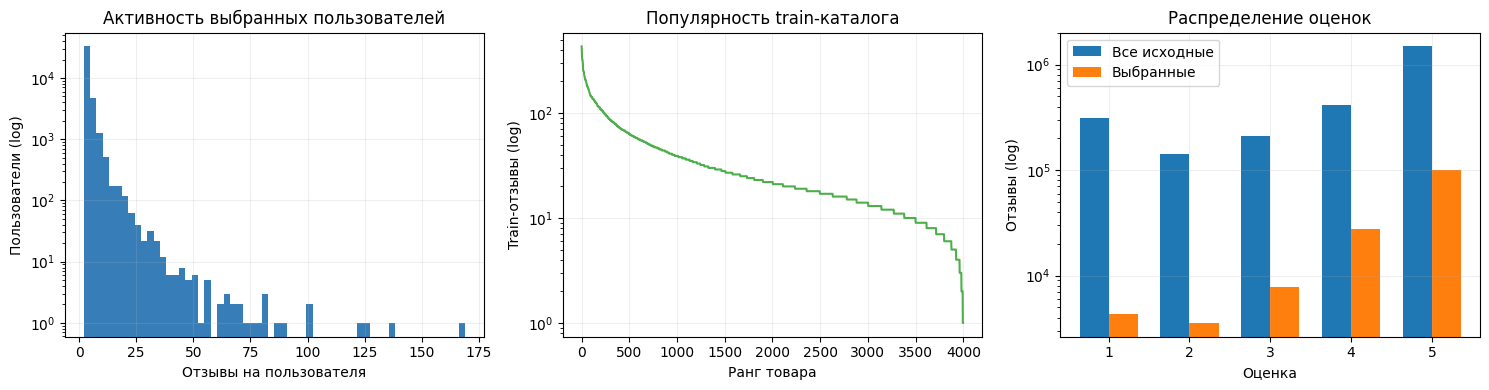

In [3]:
summary = pd.DataFrame([
    ['Исходные',len(raw),raw.user_id.nunique(),raw.item_id.nunique()],
    ['Выбранные',len(events),shape[0],shape[1]],
    ['Train',len(train),train.user_id.nunique(),train.item_id.nunique()],
    ['Validation',len(val),val.user_id.nunique(),val.item_id.nunique()],
    ['Test',len(test),test.user_id.nunique(),test.item_id.nunique()]],
    columns=['Этап','Отзывы','Пользователи','Товары'])
display(summary)
print('Пропуски исходных полей:',report['missing'])
print('Точных дубликатов:',report['exact_duplicates'])
print('Повторных user/item строк (включая точные):',report['repeated_user_item_rows'])
print(f"Разреженность выбранной матрицы: {report['sparsity']:.6%}")
display(meta[['item_id','title','brand','category']].head(8))
fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].hist(events.groupby('user_id').size(),bins=60,log=True,color='#377eb8')
axes[0].set(xlabel='Отзывы на пользователя',ylabel='Пользователи (log)',title='Активность выбранных пользователей')
pop = train.groupby('item_id').size().sort_values(ascending=False).to_numpy()
axes[1].plot(np.arange(1,len(pop)+1),pop,color='#4daf4a')
axes[1].set(yscale='log',xlabel='Ранг товара',ylabel='Train-отзывы (log)',title='Популярность train-каталога')
axes[2].bar(raw.rating.value_counts().sort_index().index-.18,raw.rating.value_counts().sort_index(),width=.36,label='Все исходные')
axes[2].bar(events.rating.value_counts().sort_index().index+.18,events.rating.value_counts().sort_index(),width=.36,label='Выбранные')
axes[2].set(yscale='log',xlabel='Оценка',ylabel='Отзывы (log)',title='Распределение оценок')
axes[2].legend()
plt.tight_layout(); plt.show()

### Признаки FM

Кроме user/item ID используем бренд, последнюю категорию и слово из названия.
Они могут связывать товары одного издателя, типа или игровой серии.

Словари строим по товарам train. Бренд должен встретиться хотя бы дважды.
Берём до 2048 частых слов из трёх и более латинских букв, встречающихся
минимум в пяти названиях. HTML и служебные слова удаляем. Для товара выбираем
самое редкое подходящее слово, при равенстве по алфавиту. Остальное кодируем
как `unknown`.

Названия, бренды и категории считаем известными в момент рекомендации.
Истории их изменений в данных нет, это ограничение эксперимента.

metadata_source_rows      84819.000000
metadata_item_coverage        0.998498
brand_coverage                0.993744
category_coverage             0.993994
dtype: float64

brand_values              224.000000
title_values              778.000000
category_values           790.000000
brand_encoded_coverage      0.916166
title_encoded_coverage      0.971972
dtype: float64

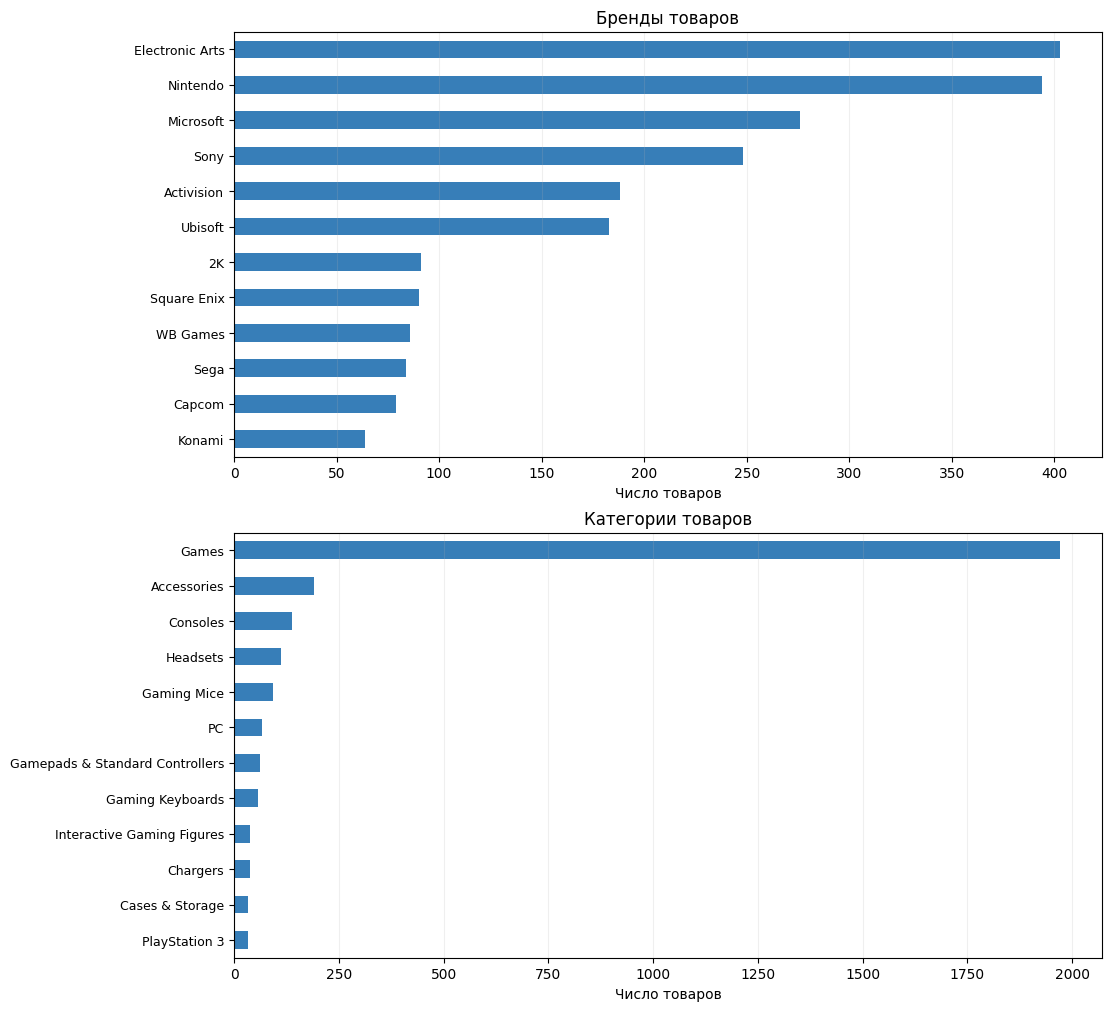

In [4]:
from textwrap import fill
from html import unescape
import re
import unicodedata

display(pd.Series({k:report[k] for k in ['metadata_source_rows','metadata_item_coverage','brand_coverage','category_coverage']}))
display(pd.Series(report['features']))

def clean_label(value):
    text = unescape(re.sub(r'<[^>]*>', ' ', str(value)))
    text = ''.join(char for char in text if unicodedata.category(char) != 'Cf')
    return ' '.join(text.split())

def last_category(values):
    if not isinstance(values, list):
        return 'Не указана'
    labels = [clean_label(value) for value in values]
    labels = [value for value in labels if value]
    return labels[-1] if labels else 'Не указана'

brands = meta.brand.fillna('').map(clean_label)
brands = brands.str.replace(r'^by\s+', '', case=False, regex=True).replace('', 'Не указан')
categories = meta.category.map(last_category)

fig, axes = plt.subplots(2, 1, figsize=(11, 10), layout='constrained')
for ax, values, title in zip(axes, [brands, categories], ['Бренды товаров', 'Категории товаров']):
    counts = values.value_counts().head(12).sort_values()
    counts.index = counts.index.map(lambda value: fill(value, width=38))
    counts.plot.barh(ax=ax, color='#377eb8')
    ax.set(title=title, xlabel='Число товаров', ylabel='')
    ax.tick_params(axis='y', labelsize=9)
    ax.grid(axis='y', visible=False)
plt.show()

## 3. Оценка

Параметры выбираем по validation, обучаясь на train. Затем обучаем лучшие
варианты на train+validation и проверяем на test. Каталог и словари фиксированы по train.

Кандидаты: весь каталог, кроме всех ранее оценённых пользователем товаров,
включая товары с низкими оценками. Новых пользователей и товары вне каталога
не оцениваем. В оценку входят пользователи хотя бы с одним будущим подходящим
товаром. У всех моделей одинаковые пользователи, кандидаты и исключения.
При равных score сортируем по ASIN.

Основная метрика для подбора: **NDCG@10**, учитывающая позиции подходящих товаров.
Вторая метрика: **Recall@10**, доля найденных будущих подходящих товаров.
Сначала считаем метрики по каждому пользователю, затем берём среднее.
Релевантность для всех моделей одинаковая: будущий отзыв на 4-5.

In [5]:
val_context = evaluation_context(train,val,shape)
print('Граница train:',pd.to_datetime(data['t0'],unit='s'),'(не включительно)')
print('Граница validation:',pd.to_datetime(data['t1'],unit='s'),'(не включительно)')
display(pd.Series(val_context['report'],name='Validation protocol'))
train_positive = matrix(train,shape,positive_only=True)
print('Положительные train-взаимодействия:',train_positive.nnz)

Граница train: 2016-03-09 00:00:00 (не включительно)
Граница validation: 2017-01-23 00:00:00 (не включительно)


relevant_rows             3154
eligible_relevant_rows    3154
excluded_cold_rows           0
excluded_seen_rows           0
evaluated_users           1888
candidate_catalog         3996
Name: Validation protocol, dtype: int64

Положительные train-взаимодействия: 123326


## 4. Модели

### Item-based CF

В `item_knn.py` используем бинарную матрицу $X_{ui}=\mathbf1[r_{ui}\ge4]$.
Сходство товаров: косинус с поправкой на число общих пользователей $n_{ij}$.

$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+\gamma}.$$

Обнуляем диагональ, оставляем $k$ соседей каждого товара. Оценки получаем из $XS$.

### iALS

В `ials.py` цель $p_{ui}=1$ для отзывов на 4-5, иначе 0.
Вес известного отзыва равен $1+\alpha$, неизвестной пары 1.
Минимизируем:

$$\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+
\lambda(\|A\|_F^2+\|B\|_F^2).$$

По очереди решаем линейные системы для факторов пользователей и товаров.
Оценка пары равна $a_u^Tb_i$.

### EASE

В `ease.py` восстанавливаем взаимодействия через другие товары:

$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\qquad\mathrm{diag}(W)=0.$$

Для $P=(X^TX+\lambda I)^{-1}$ получаем $W_{ij}=-P_{ij}/P_{jj}$ и $W_{jj}=0$.
Оценки равны $XW$. Решение находим через разложение Холецкого.

### FM

В `fm.py` учитываем взаимодействия признаков:

$$f(z)=\sum_jw_jz_j+\frac12\sum_{d=1}^D
\left[(\sum_jv_{jd}z_j)^2-\sum_jv_{jd}^2z_j^2\right].$$

Обучаем по BPR: для положительной пары $(u,i)$ берём товар $j$, который
пользователь не оценивал в train, и минимизируем
$\log(1+\exp(-(f(u,i)-f(u,j))))$ с L2-регуляризацией участвующих признаков.
На каждой эпохе выбираем по одному новому отрицательному примеру на
положительный отзыв. Градиенты и Adagrad реализованы вручную.

### iALS со своим таргетом

В `custom_ials.py` используем оценку и давность отзыва:

$$p^*_{ui}=\frac{r_{ui}-3}{2}
\left[\beta+(1-\beta)e^{-(t_{cut}-t_{ui})/(86400\tau)}\right],\qquad\beta=0.5.$$

Неизвестным парам оставляем ноль. Низкие оценки дают отрицательную цель,
высокие положительную. Давние отзывы ослабляются, сохраняя минимум половину
сигнала. $\tau$ измеряется в днях, $t_{cut}$ задаёт начало будущего периода.
Так проверяем, помогут ли сила оценки и её давность. Веса confidence
остаются теми же, что у обычного iALS; меняется именно цель обучения.

### Подбор параметров

Проверяем сетки ниже и выбираем лучший validation NDCG@10.
При равенстве берём первый вариант. Число эпох фиксировано,
test для подбора не используется.

In [6]:
classes = {'ItemKNN': ItemKNN, 'iALS': IALS, 'EASE': EASE,
           'FM+metadata': FM, 'Custom iALS': CustomIALS}
grids = {
    'ItemKNN': [{'k': 50, 'shrink': 10}, {'k': 150, 'shrink': 10},
                {'k': 100, 'shrink': 50}],
    'iALS': [{'factors': 16, 'reg': 1., 'alpha': 20., 'epochs': 6, 'seed': SEED},
             {'factors': 32, 'reg': 5., 'alpha': 20., 'epochs': 6, 'seed': SEED}],
    'EASE': [{'reg': 50.}, {'reg': 200.}, {'reg': 1000.}],
    'FM+metadata': [{'factors': 16, 'lr': lr, 'reg': .001, 'epochs': 12,
                     'batch_size': 1024, 'seed': SEED} for lr in [.03, .08]],
    'Custom iALS': [{'factors': f, 'reg': r, 'alpha': 20., 'epochs': 6,
                      'seed': SEED, 'tau_days': tau, 'floor': .5}
                    for f, r in [(16, 1.), (32, 5.)] for tau in [180., 730.]]
}

def fit_model(name, config, past, cutoff):
    return classes[name](**config).fit(
        matrix(past, shape, positive_only=True), events=past,
        cutoff=cutoff, item_features=data['item_features'])

validation_rows, selected = [], {}
for name, configs in grids.items():
    best = -np.inf
    for config in configs:
        model = fit_model(name, config, train, data['t0'])
        scores, _ = evaluate(model, val_context)
        validation_rows.append(dict(model=name, parameters=json.dumps(config), **scores))
        if scores['NDCG@10'] > best:
            selected[name] = config.copy()
            best = scores['NDCG@10']
        del model
        _ = gc.collect()

validation_table = pd.DataFrame(validation_rows)
with pd.option_context('display.max_colwidth', None):
    display(validation_table.sort_values(['model', 'NDCG@10'], ascending=[True, False]))

,model,parameters,NDCG@10,Recall@10
12,Custom iALS,"{""factors"": 32, ""reg"": 5.0, ""alpha"": 20.0, ""epochs"": 6, ""seed"": 42, ""tau_days"": 180.0, ""floor"": 0.5}",0.031611,0.055811
13,Custom iALS,"{""factors"": 32, ""reg"": 5.0, ""alpha"": 20.0, ""epochs"": 6, ""seed"": 42, ""tau_days"": 730.0, ""floor"": 0.5}",0.029521,0.052156
10,Custom iALS,"{""factors"": 16, ""reg"": 1.0, ""alpha"": 20.0, ""epochs"": 6, ""seed"": 42, ""tau_days"": 180.0, ""floor"": 0.5}",0.026779,0.045343
11,Custom iALS,"{""factors"": 16, ""reg"": 1.0, ""alpha"": 20.0, ""epochs"": 6, ""seed"": 42, ""tau_days"": 730.0, ""floor"": 0.5}",0.025892,0.043908
5,EASE,"{""reg"": 50.0}",0.032015,0.054441
6,EASE,"{""reg"": 200.0}",0.031337,0.052830
7,EASE,"{""reg"": 1000.0}",0.030996,0.051594
9,FM+metadata,"{""factors"": 16, ""lr"": 0.08, ""reg"": 0.001, ""epochs"": 12, ""batch_size"": 1024, ""seed"": 42}",0.014180,0.025877
8,FM+metadata,"{""factors"": 16, ""lr"": 0.03, ""reg"": 0.001, ""epochs"": 12, ""batch_size"": 1024, ""seed"": 42}",0.012443,0.025262
2,ItemKNN,"{""k"": 100, ""shrink"": 50}",0.029330,0.049997


## 5. Результаты

После выбора настроек обучаем модели на train+validation.
Ниже параметры и обе метрики на test.

relevant_rows             1590
eligible_relevant_rows    1590
excluded_cold_rows           0
excluded_seen_rows           0
evaluated_users           1098
candidate_catalog         3996
Name: Test protocol, dtype: int64

,parameters,NDCG@10,Recall@10
model,,,
EASE,"{""reg"": 50.0}",0.029882,0.051473
ItemKNN,"{""k"": 100, ""shrink"": 50}",0.027743,0.046967
iALS,"{""factors"": 32, ""reg"": 5.0, ""alpha"": 20.0, ""epochs"": 6, ""seed"": 42}",0.024658,0.045754
Custom iALS,"{""factors"": 32, ""reg"": 5.0, ""alpha"": 20.0, ""epochs"": 6, ""seed"": 42, ""tau_days"": 180.0, ""floor"": 0.5}",0.021721,0.040080
FM+metadata,"{""factors"": 16, ""lr"": 0.08, ""reg"": 0.001, ""epochs"": 12, ""batch_size"": 1024, ""seed"": 42}",0.017522,0.029953


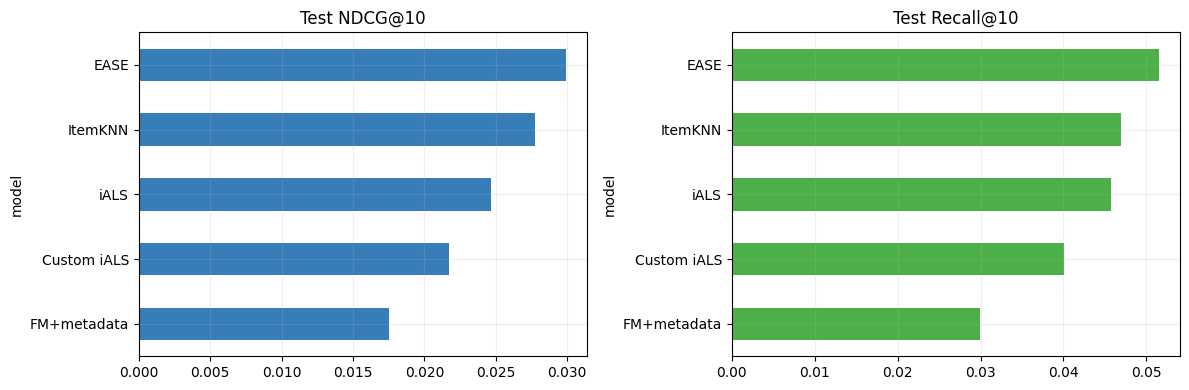

In [7]:
past = pd.concat([train, val], ignore_index=True)
test_context = evaluation_context(past, test, shape)
display(pd.Series(test_context['report'], name='Test protocol'))

final_rows = []
for name, config in selected.items():
    model = fit_model(name, config, past, data['t1'])
    scores, _ = evaluate(model, test_context)
    final_rows.append(dict(model=name, parameters=json.dumps(config), **scores))
    del model
    _ = gc.collect()

results = pd.DataFrame(final_rows).set_index('model').sort_values('NDCG@10', ascending=False)
with pd.option_context('display.max_colwidth', None):
    display(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results['NDCG@10'].sort_values().plot.barh(ax=axes[0], color='#377eb8', title='Test NDCG@10')
results['Recall@10'].sort_values().plot.barh(ax=axes[1], color='#4daf4a', title='Test Recall@10')
plt.tight_layout()
plt.show()

## 6. Выводы

Лучшей оказалась EASE с λ = 50: NDCG@10 = 0,0299 и Recall@10 = 0,0515.
На validation этот вариант тоже был лучше λ = 200 и 1000.
Второе место у item-based CF со 100 соседями и shrinkage 50.
Для iALS выбраны 32 фактора и λ = 5.

Новый таргет дал NDCG 0,0316 на validation против 0,0300 у обычного iALS,
но на test результат снизился до 0,0217 против 0,0247.
Recall тоже хуже: 0,0401 против 0,0458. Учёт оценки и давности
вместе не дал выигрыша на следующем периоде.

У FM самый низкий результат: NDCG@10 = 0,0175 и Recall@10 = 0,0300.

### Ограничения

Проверены популярные товары и пользователи с историей, холодный старт не оценивался.
Отсутствие отзыва не означает, что товар не нравится. Метаданные считаются
постоянными, так как истории изменений нет. У FM простые признаки названия
и небольшая сетка параметров. Использованы одно временное разбиение и один seed.